# XGBoost Survival Model (xgbse) — continuation of the RSF analysis

Same data prep, same 70/15/15 train/val/test split (`random_state=42`), same
tuning-on-validation-C-index approach as the RSF section above. This trains
an XGBoost-based survival model using `xgbse` (XGBoost Survival Embeddings),
then compares it head-to-head against the already-trained `rsf_final_model.pkl`
on the exact same test set and exact same time grid.

`xgbse` was chosen over raw XGBoost's `survival:cox`/`survival:aft` objectives
because it returns a full survival curve directly (comparable to RSF's
`predict_survival_function`), rather than just a risk score.

In [1]:
import numpy as np

# Compatibility shim: xgbse currently pins numpy<2, but the installed
# scikit-survival expects numpy>=2's np.trapezoid (renamed from np.trapz).
# This just points the new name at the old, still-present function.
if not hasattr(np, "trapezoid"):
    np.trapezoid = np.trapz

## 1. Data prep (identical to the RSF section)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna(subset=["TotalCharges"])
df["Churn_flag"] = (df["Churn"] == "Yes").astype(int)
df = df.drop(columns=["customerID", "Churn"])

X = df.drop(columns=["tenure", "Churn_flag", "TotalCharges"])
X = pd.get_dummies(X, drop_first=True)
bool_cols = X.select_dtypes(include="bool").columns
X[bool_cols] = X[bool_cols].astype(int)

print(X.shape)

(7032, 28)


In [3]:
from sksurv.util import Surv
from sklearn.model_selection import train_test_split

y_rsf = Surv.from_dataframe("Churn_flag", "tenure", df)

X_train, X_temp, y_rsf_train, y_rsf_temp = train_test_split(
    X, y_rsf, test_size=0.30, random_state=42
)
X_val, X_test, y_rsf_val, y_rsf_test = train_test_split(
    X_temp, y_rsf_temp, test_size=0.50, random_state=42
)

print("X Train size:", X_train.shape)
print("X Validation size:", X_val.shape)
print("X Test size:", X_test.shape)

X Train size: (4922, 28)
X Validation size: (1055, 28)
X Test size: (1055, 28)


## 2. XGBoost survival (xgbse) hyperparameter validation

Same approach as the RSF grid search: try combinations, score each on
validation C-index, keep the best. `XGBSEKaplanNeighbors` was chosen over
`XGBSEDebiasedBCE` because it's conceptually closest to what you already
understand from RSF — it finds nearest neighbors in XGBoost's leaf space and
runs Kaplan-Meier over them, same underlying idea as RSF's per-leaf KM, just
built on boosted trees instead of bagged ones.

In [4]:
from xgbse import XGBSEKaplanNeighbors
from xgbse.metrics import concordance_index
from itertools import product

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5],
    "learning_rate": [0.05, 0.1],
    "n_neighbors": [30, 50],
}

validation_results = []

for n_est, depth, lr, n_neigh in product(
        param_grid["n_estimators"], param_grid["max_depth"],
        param_grid["learning_rate"], param_grid["n_neighbors"]):

    xgb_params = {
        "objective": "survival:aft",
        "eval_metric": "aft-nloglik",
        "aft_loss_distribution": "normal",
        "aft_loss_distribution_scale": 1.0,
        "max_depth": depth,
        "learning_rate": lr,
    }

    # NOTE: xgbse's underlying XGBoost training uses the native Booster API,
    # which takes the number of boosting rounds as num_boost_round in .fit(),
    # NOT as "n_estimators" inside xgb_params (that key is silently ignored
    # by the native API — it's an sklearn-wrapper-only parameter).
    model = XGBSEKaplanNeighbors(xgb_params=xgb_params, n_neighbors=n_neigh)
    model.fit(X_train, y_rsf_train, num_boost_round=n_est)

    val_surv = model.predict(X_val)
    c_index = concordance_index(y_rsf_val, val_surv, risk_strategy="mean")

    print(f"n_est={n_est:>3}, depth={depth}, lr={lr}, neighbors={n_neigh:>2} "
          f"\u2192 C-index: {c_index:.4f}")

    validation_results.append({
        "n_estimators": n_est, "max_depth": depth,
        "learning_rate": lr, "n_neighbors": n_neigh,
        "validation_c_index": c_index,
    })

results_df = pd.DataFrame(validation_results)
print("\nTop models:")
display(results_df.sort_values("validation_c_index", ascending=False).head(10))

best_params = results_df.loc[results_df["validation_c_index"].idxmax()]
print("\nBest hyperparameters:")
print(best_params)

/usr/local/lib/python3.12/dist-packages/xgbse/non_parametric.py:61: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  return pd.DataFrame(C_exp).fillna(method="bfill").fillna(method="ffill").values


n_est=100, depth=3, lr=0.05, neighbors=30 → C-index: 0.8526


/usr/local/lib/python3.12/dist-packages/xgbse/non_parametric.py:61: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  return pd.DataFrame(C_exp).fillna(method="bfill").fillna(method="ffill").values


n_est=100, depth=3, lr=0.05, neighbors=50 → C-index: 0.8602


/usr/local/lib/python3.12/dist-packages/xgbse/non_parametric.py:61: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  return pd.DataFrame(C_exp).fillna(method="bfill").fillna(method="ffill").values


...

n_est=200, depth=5, lr=0.1, neighbors=30 → C-index: 0.8546


/usr/local/lib/python3.12/dist-packages/xgbse/non_parametric.py:61: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  return pd.DataFrame(C_exp).fillna(method="bfill").fillna(method="ffill").values


n_est=200, depth=5, lr=0.1, neighbors=50 → C-index: 0.8587

Top models:


,n_estimators,max_depth,learning_rate,n_neighbors,validation_c_index
7,100,5,0.10,50,0.863342
13,200,5,0.05,50,0.862624
1,100,3,0.05,50,0.860196
3,100,3,0.10,50,0.860161
9,200,3,0.05,50,0.859547
5,100,5,0.05,50,0.858963
15,200,5,0.10,50,0.858715
11,200,3,0.10,50,0.857745
2,100,3,0.10,30,0.855928
8,200,3,0.05,30,0.855718



Best hyperparameters:
n_estimators          100.000000
max_depth               5.000000
learning_rate           0.100000
n_neighbors            50.000000
validation_c_index      0.863342
Name: 7, dtype: float64


## 3. Retrain on train + validation combined, using best hyperparameters

In [5]:
X_train_final = pd.concat([X_train, X_val], axis=0)
y_train_final = np.concatenate([y_rsf_train, y_rsf_val])

best_xgb_params = {
    "objective": "survival:aft",
    "eval_metric": "aft-nloglik",
    "aft_loss_distribution": "normal",
    "aft_loss_distribution_scale": 1.0,
    "max_depth": int(best_params["max_depth"]),
    "learning_rate": float(best_params["learning_rate"]),
}
best_num_boost_round = int(best_params["n_estimators"])

xgbse_final = XGBSEKaplanNeighbors(
    xgb_params=best_xgb_params,
    n_neighbors=int(best_params["n_neighbors"]),
)
xgbse_final.fit(X_train_final, y_train_final, num_boost_round=best_num_boost_round)

print("Final xgbse model trained")
print("Hyperparameters:", best_xgb_params,
      "| num_boost_round:", best_num_boost_round,
      "| n_neighbors:", int(best_params["n_neighbors"]))

Final xgbse model trained
Hyperparameters: {'objective': 'survival:aft', 'eval_metric': 'aft-nloglik', 'aft_loss_distribution': 'normal', 'aft_loss_distribution_scale': 1.0, 'max_depth': 5, 'learning_rate': 0.1} | num_boost_round: 100 | n_neighbors: 50


In [6]:
import joblib
joblib.dump(xgbse_final, "xgbse_final_model.pkl")
print("Model saved")

Model saved


## 4. Test set evaluation

Two C-index numbers are reported for xgbse:
- **xgbse's own `concordance_index`** — the library's recommended metric.
- **sksurv's `concordance_index_censored`**, fed a risk score derived from
  each customer's predicted survival curve — this uses the *exact same
  function* your RSF's C-index came from (`rsf_final.score()` calls this
  under the hood), so it's the fairest possible head-to-head number.

In [7]:
from sksurv.metrics import concordance_index_censored

test_surv_xgbse = xgbse_final.predict(X_test)

# xgbse's own recommended metric
test_c_index_xgbse_native = concordance_index(y_rsf_test, test_surv_xgbse, risk_strategy="mean")

# sksurv's metric (same function used for RSF), fed a risk score derived from the curve:
# higher area under the survival curve = lower risk, so negate it to get a risk score
risk_score_xgbse = -np.trapz(test_surv_xgbse.values, x=test_surv_xgbse.columns.values.astype(float), axis=1)
test_c_index_xgbse_sksurv = concordance_index_censored(
    y_rsf_test["Churn_flag"].astype(bool), y_rsf_test["tenure"], risk_score_xgbse
)[0]

print(f"XGBoost (xgbse) Test C-index (xgbse native)  : {test_c_index_xgbse_native:.4f}")
print(f"XGBoost (xgbse) Test C-index (sksurv metric)  : {test_c_index_xgbse_sksurv:.4f}")

/usr/local/lib/python3.12/dist-packages/xgbse/non_parametric.py:61: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  return pd.DataFrame(C_exp).fillna(method="bfill").fillna(method="ffill").values


XGBoost (xgbse) Test C-index (xgbse native)  : 0.8494
XGBoost (xgbse) Test C-index (sksurv metric)  : 0.8472


## 5. Integrated Brier Score — on the exact same time grid as RSF

`xgbse` supports requesting predictions at specific time points, so this
evaluates both models on identical months, not just a similar range.

In [8]:
from sksurv.metrics import integrated_brier_score, brier_score

train_event_times = np.unique(y_train_final["tenure"][y_train_final["Churn_flag"]])
test_event_times = y_rsf_test["tenure"]

times = train_event_times[
    (train_event_times > test_event_times.min()) &
    (train_event_times < test_event_times.max())
]

print(f"Evaluating IBS from month {times.min()} to month {times.max()}")

# Request xgbse predictions at this EXACT same time grid
surv_probs_xgbse_grid = xgbse_final.predict(X_test, time_bins=times).values

ibs_xgbse = integrated_brier_score(y_train_final, y_rsf_test, surv_probs_xgbse_grid, times)
print(f"XGBoost (xgbse) Test IBS: {ibs_xgbse:.4f}")

Evaluating IBS from month 2.0 to month 71.0


XGBoost (xgbse) Test IBS: 0.0924


/usr/local/lib/python3.12/dist-packages/xgbse/non_parametric.py:61: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  return pd.DataFrame(C_exp).fillna(method="bfill").fillna(method="ffill").values


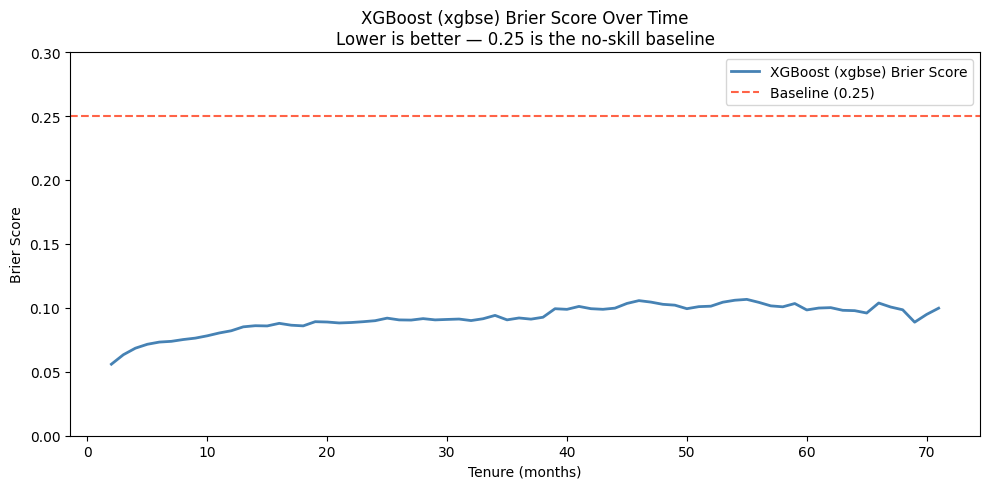

In [9]:
times_bs, bs_xgbse = brier_score(y_train_final, y_rsf_test, surv_probs_xgbse_grid, times)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(times_bs, bs_xgbse, linewidth=2, color="steelblue", label="XGBoost (xgbse) Brier Score")
ax.axhline(0.25, color="tomato", linestyle="--", linewidth=1.5, label="Baseline (0.25)")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Brier Score")
ax.set_title("XGBoost (xgbse) Brier Score Over Time\nLower is better \u2014 0.25 is the no-skill baseline")
ax.set_ylim(0, 0.30)
ax.legend()
plt.tight_layout()
plt.show()

## 6. Head-to-head: RSF vs. XGBoost (xgbse)

Loads your actual `rsf_final_model.pkl` and scores it on this exact same
`X_test` / `y_rsf_test` / `times` grid, so both rows in this table come from
identical data, identical metrics, identical evaluation code.

In [10]:
rsf_final = joblib.load("rsf_final_model.pkl")

rsf_train_c = rsf_final.score(X_train_final, y_train_final)
rsf_test_c = rsf_final.score(X_test, y_rsf_test)

rsf_surv_functions = rsf_final.predict_survival_function(X_test)
rsf_surv_probs = np.asarray([fn(times) for fn in rsf_surv_functions])
rsf_ibs = integrated_brier_score(y_train_final, y_rsf_test, rsf_surv_probs, times)

xgbse_train_surv = xgbse_final.predict(X_train_final)
xgbse_train_c = concordance_index(y_train_final, xgbse_train_surv, risk_strategy="mean")

comparison = pd.DataFrame([
    {"Model": "Random Survival Forest", "Train C-index": rsf_train_c,
     "Test C-index": rsf_test_c, "Test IBS": rsf_ibs},
    {"Model": "XGBoost (xgbse)", "Train C-index": xgbse_train_c,
     "Test C-index": test_c_index_xgbse_sksurv, "Test IBS": ibs_xgbse},
])

display(comparison.round(4))

/usr/local/lib/python3.12/dist-packages/xgbse/non_parametric.py:61: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  return pd.DataFrame(C_exp).fillna(method="bfill").fillna(method="ffill").values


,Model,Train C-index,Test C-index,Test IBS
0,Random Survival Forest,0.8623,0.8480,0.0932
1,XGBoost (xgbse),0.8692,0.8472,0.0924


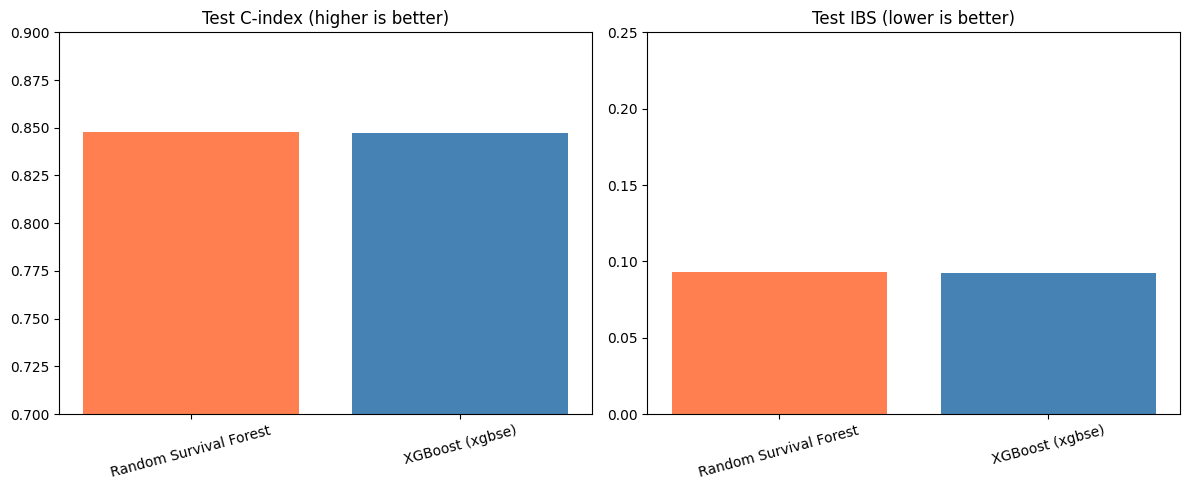

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(comparison["Model"], comparison["Test C-index"], color=["coral", "steelblue"])
axes[0].set_title("Test C-index (higher is better)")
axes[0].set_ylim(0.7, 0.9)

axes[1].bar(comparison["Model"], comparison["Test IBS"], color=["coral", "steelblue"])
axes[1].set_title("Test IBS (lower is better)")
axes[1].set_ylim(0, max(0.25, comparison["Test IBS"].max() * 1.2))

for ax in axes:
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

## Takeaway

Both models are evaluated on the same test set, the same time grid, and the
same underlying metric functions (`concordance_index_censored` and
`integrated_brier_score` from `sksurv`) — so the numbers above are a fair
comparison, not just two separately-reported scores. Whichever model wins on
your run, the reasoning to report is: C-index tells you which model *ranks*
customers by risk more correctly; IBS tells you which model's actual
predicted *probabilities* are better calibrated, not just the ranking.